In [5]:
import seabreeze.spectrometers as sb

import matplotlib.pyplot as plt
import numpy as np
import time

In [6]:
spec = sb.Spectrometer.from_serial_number("S03615")#STS-UV-L-100-400-SMA
#set integration time
micro_time=.2*1e6 # us
spec.integration_time_micros(micro_time)

### random functional test

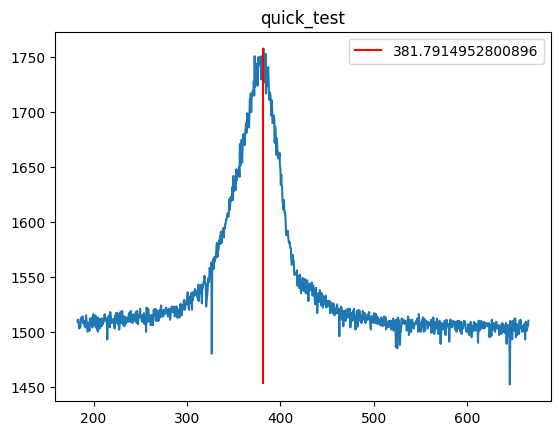

In [57]:
nm,ints = spec.spectrum()
plt.plot(nm,ints)
# plt.plot(nm,ints-dark_)
plt.vlines(nm[np.argmax(ints)],np.min(ints),np.max(ints),color='r',label=nm[np.argmax(ints)])
plt.title('quick_test'.format(micro_time/1e3))
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

## measure the darknoise

In [38]:
dark_ = []
for _ in range(10):
    _,ints = spec.spectrum()
    dark_.append(ints)
    time.sleep(6)
dark_ =np.asarray(dark_)

In [41]:
dark_200ms = np.mean(dark_,axis=0)

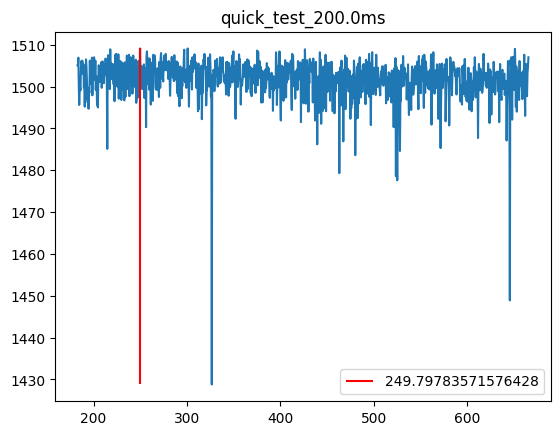

In [62]:
plt.plot(nm,dark_200ms)
plt.vlines(nm[np.argmax(dark_200ms)],np.min(dark_200ms),np.max(dark_200ms),color='r',label=nm[np.argmax(dark_200ms)])
plt.title(f'quick_test_{micro_time/1e3}ms')
# plt.ylim(np.min(ints),np.max(ints))
plt.legend()

### measure aura3 blue (allegedly 475nm)

In [48]:
blue_aura3 = []
for _ in range(10):
    _,ints = spec.spectrum()
    blue_aura3.append(ints)
    time.sleep(6)
blue_aura3_200ms = np.mean(np.asarray(blue_aura3),axis=0)
clean_blue_aura3_200ms = blue_aura3_200ms-dark_200ms

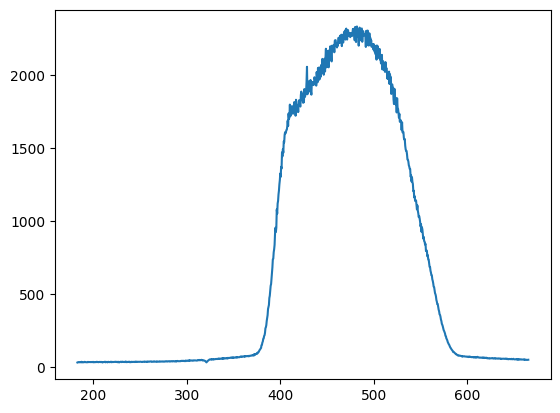

In [54]:
plt.plot(nm,clean_blue_aura3_200ms)

###  measure aura3 uv (allegedly 395nm)

In [ ]:
uv_aura3 = []
for _ in range(10):
    _,ints = spec.spectrum()
    uv_aura3.append(ints)
    time.sleep(6)
uv_aura3_200ms = np.mean(np.asarray(uv_aura3),axis=0)
clean_uv_aura3_200ms = uv_aura3_200ms-dark_200ms

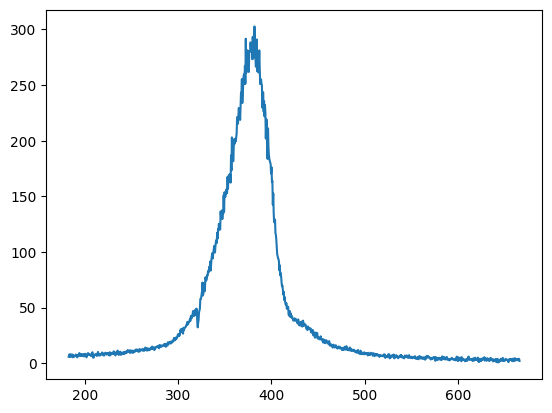

In [59]:
plt.plot(nm,clean_uv_aura3_200ms)

## save the aura3_sts_UV_100 calibration file

In [64]:
nm = nm
int_t = micro_time
uv_input = [(1,0,0),(0,0,1)]
blue_input = [(1,0,0),(0,3,0)]
dark_avg = dark_200ms
clean_uv = clean_uv_aura3_200ms
clean_blue = clean_blue_aura3_200ms

In [65]:
np.savez('./aura3_stsuv100_calibration22122025.npz',
         nm=nm,int_t=int_t,
         uv_input=uv_input,
         blue_input=blue_input,
         dark_avg=dark_avg,
         clean_uv=clean_uv,
         clean_blue=clean_blue)